## 双色球组合策略

### 加载数据

In [2]:
import pandas as pd  # 导入pandas库，用于数据处理
def load_history(path='history.csv') -> pd.DataFrame:
    """加载历史双色球数据，并返回 DataFrame"""
    df = pd.read_csv(path, dtype=str)
    red_cols = ['红球1', '红球2', '红球3', '红球4', '红球5', '红球6']
    for col in red_cols + ['蓝球']:
        df[col] = df[col].astype(int)
    return df


In [3]:
def get_recent_30(df: pd.DataFrame) -> pd.DataFrame:
    """返回最近30期的数据"""
    return df.tail(30).reset_index(drop=True)


## 冷热号计算

In [4]:
def compute_red_hot_cold(df_30: pd.DataFrame):
    """统计最近30期红球频率，返回热号集、冷号集"""
    reds = df_30[['红球1', '红球2', '红球3', '红球4', '红球5', '红球6']].values.flatten()
    red_counts = pd.Series(reds).value_counts().sort_index()
    avg = red_counts.mean()
    hot = red_counts[red_counts > avg].index.tolist()
    cold = red_counts[red_counts <= avg].index.tolist()
    return hot, cold
def compute_blue_cold(df_30: pd.DataFrame):
    """统计最近30期蓝球频率，返回冷号集（<=平均）"""
    blue_counts = df_30['蓝球'].astype(int).value_counts().sort_index()
    full = blue_counts.reindex(range(1, 17), fill_value=0)
    avg = full.mean()
    cold_blues = full[full <= avg].index.tolist()
    return cold_blues

## 号码生成函数

In [5]:
import random

def generate_red_ball(hot, cold):
    """生成1组红球：从热号中选3个，冷号中选3个，组合打乱"""
    red = random.sample(hot, 3) + random.sample(cold, 3)
    return sorted(red)
def generate_blue_ball(cold_blues):
    """从冷号中随机选出一个蓝球"""
    return random.choice(cold_blues)


### 冲突过滤

In [6]:
def is_conflict(new_reds, new_blue, history_df) -> bool:
    """判断该组号码是否与历史重复或冲突"""
    for _, row in history_df.iterrows():
        hist_red = [row[f'红球{i}'] for i in range(1, 7)]
        hist_blue = row['蓝球']
        same_red_count = len(set(new_reds) & set(hist_red))
        if same_red_count == 6:
            return True
        if same_red_count == 5 and new_blue == hist_blue:
            return True
        if same_red_count == 6 and new_blue == hist_blue:
            return True
    return False


## 主函数

In [7]:
def generate_unique_recommendation(df_full, df_30, max_retry=1000):
    """生成不与历史冲突的推荐号码组合"""
    hot, cold = compute_red_hot_cold(df_30)
    cold_blues = compute_blue_cold(df_30)
    
    for _ in range(max_retry):
        red = generate_red_ball(hot, cold)
        blue = generate_blue_ball(cold_blues)
        if not is_conflict(red, blue, df_full):
            return red, blue
    raise ValueError("无法在限制内生成不冲突的组合")


## 使用

In [8]:
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
from update_data import update_history
#from visualize import visualize_history

update_history()

df_all = load_history('history.csv')
df_recent = get_recent_30(df_all)

for i in range(5):
    red, blue = generate_unique_recommendation(df_all, df_recent)
    print(f"第{i+1}注：红球 {red} | 蓝球 {blue}")



无新增记录，无需更新。
最新一期：25110，红球：1 5 11 14 16 19，蓝球：8
第1注：红球 [9, 11, 12, 21, 26, 28] | 蓝球 10
第2注：红球 [1, 4, 16, 19, 26, 28] | 蓝球 9
第3注：红球 [5, 13, 17, 25, 30, 32] | 蓝球 10
第4注：红球 [2, 5, 7, 15, 19, 25] | 蓝球 11
第5注：红球 [5, 9, 10, 16, 28, 29] | 蓝球 9


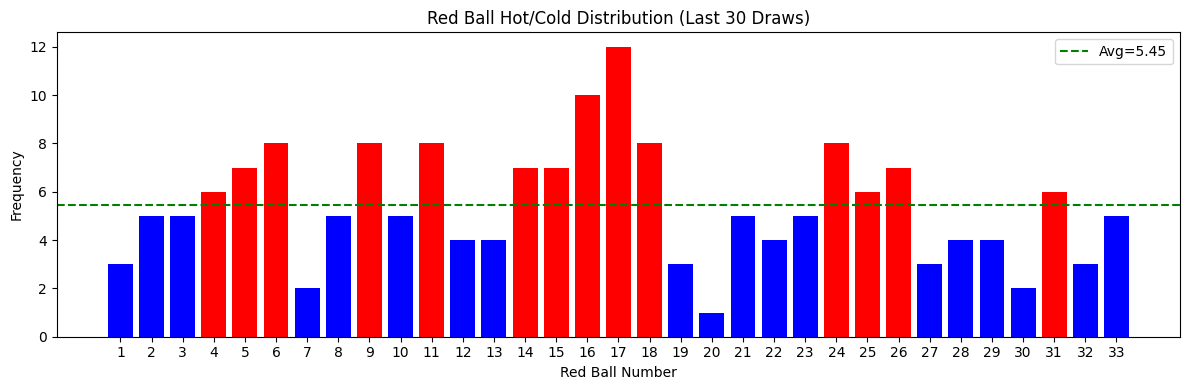

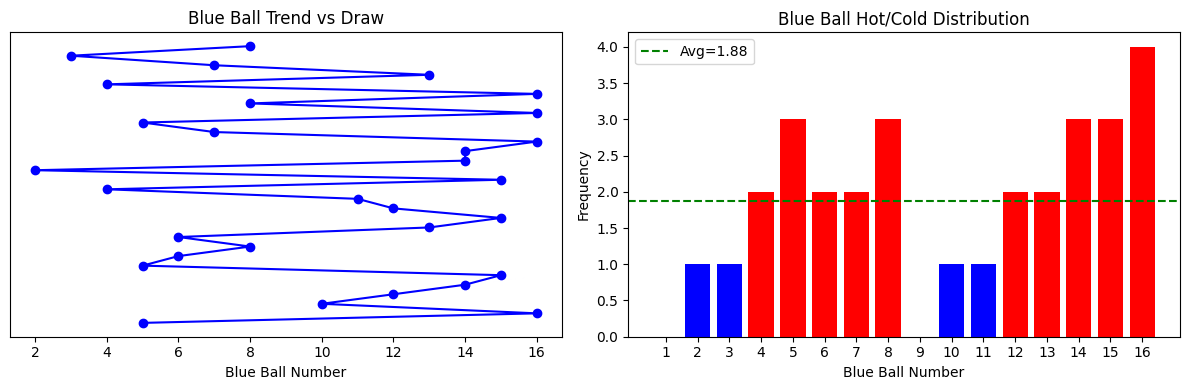

In [9]:
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

import pandas as pd
import matplotlib.pyplot as plt

# —— 1. 读取 CSV 最后 30 条记录 —— 
df = pd.read_csv('history.csv', dtype=str)
df = df.tail(30).reset_index(drop=True)


# —— 2. 红球频次统计 —— 
# 将红球1~6列合并为一个 Series，并转为整数
red_columns = ['红球1', '红球2', '红球3', '红球4', '红球5', '红球6']
reds_flat = df[red_columns].values.flatten().astype(int)
red_freq = pd.Series(reds_flat).value_counts().sort_index()
avg_red = red_freq.mean()

# —— 3. 红球可视化 —— 
plt.figure(figsize=(12, 4))
colors_red = ['red' if f > avg_red else 'blue' for f in red_freq.values]
plt.bar(red_freq.index, red_freq.values, color=colors_red)
plt.axhline(avg_red, color='green', linestyle='--', label=f'Avg={avg_red:.2f}')
plt.xlabel('Red Ball Number')
plt.ylabel('Frequency')
plt.title('Red Ball Hot/Cold Distribution (Last 30 Draws)')
plt.xticks(range(1, 34))
plt.legend()
plt.tight_layout()
plt.show()

# —— 4. 蓝球走势与频次 —— 
blue_nums = df['蓝球'].astype(int)
blue_freq = blue_nums.value_counts().sort_index()
blue_freq_full = blue_freq.reindex(range(1, 17), fill_value=0)
avg_blue = blue_freq_full.mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 4.1 折线图：蓝球走势（纵轴是期号）
axes[0].plot(
    blue_nums.values,
    df['期号'],
    marker='o',
    linestyle='-',
    color='blue'
)
axes[0].set_xlabel('Blue Ball Number')
axes[0].set_ylabel('Draw Number')
axes[0].set_title('Blue Ball Trend vs Draw')
axes[0].get_yaxis().set_visible(False)

# 4.2 柱状图：蓝球频率分布
colors_blue = ['red' if f > avg_blue else 'blue' for f in blue_freq_full.values]
axes[1].bar(blue_freq_full.index, blue_freq_full.values, color=colors_blue)
axes[1].axhline(avg_blue, color='green', linestyle='--', label=f'Avg={avg_blue:.2f}')
axes[1].set_xlabel('Blue Ball Number')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Blue Ball Hot/Cold Distribution')
axes[1].set_xticks(range(1, 17))
axes[1].legend()

plt.tight_layout()
plt.show()


## Enhance 策略

### 奇偶/号段均衡控制

In [10]:
def generate_balanced_reds(hot_pool, cold_pool):
    """
    生成一组红球，满足以下增强条件：
    - 奇偶数比例在 2:4, 3:3, 4:2 之间
    - 三个号段（1-11, 12-22, 23-33）至少覆盖两个段
    - 热号+冷号混合生成
    """
    all_pool = hot_pool + cold_pool
    tries = 0
    while tries < 1000:
        candidate = sorted(random.sample(all_pool, 6))
        odds = [n for n in candidate if n % 2 == 1]
        evens = [n for n in candidate if n % 2 == 0]
        sections = set()
        for n in candidate:
            if n <= 11:
                sections.add(1)
            elif n <= 22:
                sections.add(2)
            else:
                sections.add(3)
        # 满足奇偶 + 段数 >= 2
        if 2 <= len(odds) <= 4 and len(sections) >= 2:
            return candidate
        tries += 1
    raise ValueError("无法生成满足增强策略的红球组合")